# Lab 6

You are tasked with evaluating card counting strategies for black jack. In order to do so, you will use object oriented programming to create a playable casino style black jack game where a computer dealer plays against $n$ computer players and possibly one human player. If you don't know the rules of blackjack or card counting, please google it. 

A few requirements:
* The game should utilize multiple 52-card decks. Typically the game is played with 6 decks.
* Players should have chips.
* Dealer's actions are predefined by rules of the game (typically hit on 16). 
* The players should be aware of all shown cards so that they can count cards.
* Each player could have a different strategy.
* The system should allow you to play large numbers of games, study the outcomes, and compare average winnings per hand rate for different strategies.

1. Begin by creating a classes to represent cards and decks. The deck should support more than one 52-card set. The deck should allow you to shuffle and draw cards. Include a "plastic" card, placed randomly in the deck. Later, when the plastic card is dealt, shuffle the cards before the next deal.

In [3]:


# Exercise 1
# Card and Deck classes for Blackjack

import random


# Class to represent a playing card
class Card:

    def __init__(self, rank, suit):
        self.rank = rank
        self.suit = suit

    # Check if this is the plastic card
    def is_plastic(self):
        return self.rank == "PLASTIC"

    # Return the blackjack value of the card
    def value(self):
        if self.is_plastic():
            return 0

        if self.rank in ["J", "Q", "K"]:
            return 10

        if self.rank == "A":
            return 11

        return int(self.rank)

    # Display the card
    def __str__(self):
        if self.is_plastic():
            return "PLASTIC CARD"

        return self.rank + " of " + self.suit


# Class to represent multiple decks of cards
class Deck:

    def __init__(self, num_decks=6):
        if num_decks < 1:
            raise ValueError("Number of decks must be positive")

        self.num_decks = num_decks
        self.cards = []
        self.shuffle_needed = False

        self.shuffle()

    # Create and shuffle the deck
    def shuffle(self):
        suits = ["Hearts", "Diamonds", "Clubs", "Spades"]
        ranks = ["A", "2", "3", "4", "5", "6",
                 "7", "8", "9", "10", "J", "Q", "K"]

        self.cards = []

        # Add each standard 52-card deck
        for d in range(self.num_decks):
            for suit in suits:
                for rank in ranks:
                    self.cards.append(Card(rank, suit))

        # Randomize the cards
        random.shuffle(self.cards)

        # Add the plastic card at a random position
        position = random.randint(0, len(self.cards))
        self.cards.insert(position, Card("PLASTIC", None))

        self.shuffle_needed = False

    # Draw one card
    def draw(self):

        # Reshuffle before the next draw if needed
        if self.shuffle_needed or len(self.cards) == 0:
            self.shuffle()

        card = self.cards.pop()

        # The plastic card signals a future shuffle
        if card.is_plastic():
            self.shuffle_needed = True

        return card

    # Count how many cards remain
    def remaining_cards(self):
        return len(self.cards)



# Exercise 1 - Test 


print("Testing Card and Deck classes\n")

# Test 1: Check if the classes were created
print("Card class defined:", Card)
print("Deck class defined:", Deck)

# Test 2: Create six decks
deck = Deck(6)

print("\nSix-deck card count:", deck.remaining_cards())
assert deck.remaining_cards() == 313

# Test 3: Check card values
king = Card("K", "Hearts")
five = Card("5", "Clubs")
ace = Card("A", "Spades")

print("\nKing value:", king.value())
print("Five value:", five.value())
print("Ace value:", ace.value())

assert king.value() == 10
assert five.value() == 5
assert ace.value() == 11

# Test 4: Draw a card
card = deck.draw()

print("\nCard drawn:", card)
print("Cards remaining:", deck.remaining_cards())

assert deck.remaining_cards() == 312

# Test 5: Create a single deck
small_deck = Deck(1)

print("\nSingle-deck card count:",
      small_deck.remaining_cards())

assert small_deck.remaining_cards() == 53

# Test 6: Test the plastic card
test_deck = Deck(1)

# Put the plastic card on top for testing
test_deck.cards = [
    Card("5", "Hearts"),
    Card("PLASTIC", None)
]

plastic = test_deck.draw()

print("\nPlastic card drawn:", plastic)
print("Shuffle needed:", test_deck.shuffle_needed)

assert plastic.is_plastic() == True
assert test_deck.shuffle_needed == True

# The next draw should trigger a reshuffle
next_card = test_deck.draw()

print("\nCard after reshuffling:", next_card)
print("Cards remaining:",
      test_deck.remaining_cards())

assert test_deck.remaining_cards() == 52

# Final result
print("\nExercise 1 tests passed!")



Testing Card and Deck classes

Card class defined: <class '__main__.Card'>
Deck class defined: <class '__main__.Deck'>

Six-deck card count: 313

King value: 10
Five value: 5
Ace value: 11

Card drawn: 8 of Spades
Cards remaining: 312

Single-deck card count: 53

Plastic card drawn: PLASTIC CARD
Shuffle needed: True

Card after reshuffling: 3 of Clubs
Cards remaining: 52

Exercise 1 tests passed!


2. Now design your game on a UML diagram. You may want to create classes to represent, players, a hand, and/or the game. As you work through the lab, update your UML diagram. At the end of the lab, submit your diagram (as pdf file) along with your notebook. 

3. Begin with implementing the skeleton (ie define data members and methods/functions, but do not code the logic) of the classes in your UML diagram.

In [4]:

# Exercise 3



# Class to represent a player's hand
class Hand:

    def __init__(self):
        self.cards = []

    # Add a card to the hand
    def add_card(self, card):
        pass

    # Calculate the total value of the hand
    def value(self):
        pass

    # Check if the hand is over 21
    def is_bust(self):
        pass

    # Remove all cards from the hand
    def clear(self):
        pass


# Base class for all players
class Player:

    def __init__(self, name, chips=100):
        self.name = name
        self.chips = chips
        self.hand = Hand()
        self.bet = 0

    # Place a bet using chips
    def place_bet(self, amount):
        pass

    # Receive a card
    def receive_card(self, card):
        pass

    # Decide whether to hit or stand
    def choose_action(self):
        pass

    # Reset the hand for the next round
    def reset_hand(self):
        pass


# Dealer class inherits from Player
class Dealer(Player):

    def __init__(self):
        super().__init__("Dealer", 0)

    # Dealer follows blackjack rules
    def choose_action(self):
        pass


# Human player class
class HumanPlayer(Player):

    # Human decides whether to hit or stand
    def choose_action(self):
        pass


# Computer player class
class ComputerPlayer(Player):

    # Computer follows a basic strategy
    def choose_action(self):
        pass


# Computer player that counts cards
class CountingPlayer(ComputerPlayer):

    def __init__(self, name, chips=100, threshold=0):
        super().__init__(name, chips)

        self.running_count = 0
        self.threshold = threshold

    # Update the count when a card is shown
    def observe_card(self, card):
        pass

    # Reset the count after shuffling
    def reset_count(self):
        pass

    # Make a decision using the card count
    def choose_action(self):
        pass


# Main class to control the blackjack game
class BlackjackGame:

    def __init__(self, num_decks=6, players=None):
        self.deck = Deck(num_decks)
        self.dealer = Dealer()

        if players is None:
            self.players = []
        else:
            self.players = players

        self.visible_cards = []

    # Deal a card to a hand
    def deal_card(self, hand):
        pass

    # Play one round of blackjack
    def play_round(self, verbose=True):
        pass

    # Play several rounds
    def play_rounds(self, n, verbose=False):
        pass

    # Determine winning and losing bets
    def settle_bets(self):
        pass

    # Show a card to all players
    def show_card(self, card):
        pass



# Exercise 3 


print("Testing Blackjack classes\n")

# Create a hand
hand = Hand()
print("Hand created:", hand.cards)

# Create players
player1 = HumanPlayer("Player 1", 100)
player2 = ComputerPlayer("Computer 1", 100)
player3 = CountingPlayer("Counter 1", 100, 0)

# Create a dealer
dealer = Dealer()

print("Human player:", player1.name)
print("Computer player:", player2.name)
print("Counting player:", player3.name)
print("Dealer:", dealer.name)

# Create a blackjack game
game = BlackjackGame(6, [player1, player2, player3])

print("\nNumber of players:", len(game.players))
print("Number of cards:", game.deck.remaining_cards())
print("Player starting chips:", player1.chips)
print("Initial running count:", player3.running_count)

# Test the basic attributes and inheritance
assert hand.cards == []
assert player1.chips == 100
assert player2.chips == 100
assert player3.running_count == 0
assert len(game.players) == 3
assert game.deck.remaining_cards() == 313

assert isinstance(dealer, Player)
assert isinstance(player1, Player)
assert isinstance(player2, Player)
assert isinstance(player3, ComputerPlayer)

# Check that the method skeletons exist
assert callable(game.play_round)
assert callable(game.play_rounds)
assert callable(game.settle_bets)
assert callable(player1.choose_action)
assert callable(player3.observe_card)
assert callable(hand.value)

print("\nExercise 3 tests passed!")


Testing Blackjack classes

Hand created: []
Human player: Player 1
Computer player: Computer 1
Counting player: Counter 1
Dealer: Dealer

Number of players: 3
Number of cards: 313
Player starting chips: 100
Initial running count: 0

Exercise 3 tests passed!


4. Complete the implementation by coding the logic of all functions. For now, just implement the dealer player and human player.

In [5]:

# Exercise 4
# blackjack game time




# Class to represent a hand of cards
class Hand:

    def __init__(self):
        self.cards = []

    # Add a card to the hand
    def add_card(self, card):
        if card.is_plastic():
            raise ValueError("Cannot add plastic card to a hand")

        self.cards.append(card)

    # Calculate the hand's blackjack value
    def value(self):
        total = 0
        aces = 0

        for card in self.cards:
            total += card.value()

            if card.rank == "A":
                aces += 1

        # Count an Ace as 1 instead of 11 when necessary
        while total > 21 and aces > 0:
            total -= 10
            aces -= 1

        return total

    # Check whether the hand is over 21
    def is_bust(self):
        return self.value() > 21

    # Check for a natural blackjack
    def is_blackjack(self):
        return len(self.cards) == 2 and self.value() == 21

    # Empty the hand
    def clear(self):
        self.cards = []


# Base class for blackjack players
class Player:

    def __init__(self, name, chips=100):
        self.name = name
        self.chips = chips
        self.hand = Hand()
        self.bet = 0

    # Place a bet
    def place_bet(self, amount):
        if amount <= 0 or amount > self.chips:
            raise ValueError("Invalid bet amount")

        self.bet = amount
        self.chips -= amount

    # Receive a new card
    def receive_card(self, card):
        self.hand.add_card(card)

    # Method to be implemented by player types
    def choose_action(self):
        raise NotImplementedError

    # Prepare for a new round
    def reset_hand(self):
        self.hand.clear()
        self.bet = 0


# Dealer follows fixed blackjack rules
class Dealer(Player):

    def __init__(self):
        super().__init__("Dealer", 0)

    def choose_action(self):
        if self.hand.value() < 17:
            return "hit"

        return "stand"


# Human player makes decisions using keyboard input
class HumanPlayer(Player):

    def choose_action(self):
        action = input(
            self.name + " - hit or stand? "
        ).strip().lower()

        while action not in ["hit", "stand"]:
            action = input(
                "Please enter hit or stand: "
            ).strip().lower()

        return action


# Placeholder for the computer strategy in later exercises
class ComputerPlayer(Player):

    def choose_action(self):
        pass


# Placeholder for the card-counting strategy
class CountingPlayer(ComputerPlayer):

    def __init__(self, name, chips=100, threshold=0):
        super().__init__(name, chips)
        self.running_count = 0
        self.threshold = threshold

    def observe_card(self, card):
        pass

    def reset_count(self):
        pass

    def choose_action(self):
        pass


# Main class for managing blackjack
class BlackjackGame:

    def __init__(self, num_decks=6, players=None):
        self.deck = Deck(num_decks)
        self.dealer = Dealer()

        if players is None:
            self.players = []
        else:
            self.players = players

        self.visible_cards = []

    # Deal a card to a hand
    def deal_card(self, hand, visible=True):
        card = self.deck.draw()

        # Skip the plastic card and reshuffle
        while card.is_plastic():
            card = self.deck.draw()

        hand.add_card(card)

        if visible:
            self.show_card(card)

        return card

    # Record cards that have been revealed
    def show_card(self, card):
        self.visible_cards.append(card)

    # Determine each player's result and pay winnings
    def settle_bets(self):
        results = {}

        for player in self.players:

            if player.bet == 0:
                continue

            # Player loses if their hand exceeds 21
            if player.hand.is_bust():
                result = "lose"

            # Check whether dealer has blackjack
            elif self.dealer.hand.is_blackjack():
                if player.hand.is_blackjack():
                    player.chips += player.bet
                    result = "push"
                else:
                    result = "lose"

            # Player blackjack pays 3 to 2
            elif player.hand.is_blackjack():
                player.chips += 2.5 * player.bet
                result = "blackjack"

            # Player wins if dealer busts or has lower total
            elif (self.dealer.hand.is_bust() or
                  player.hand.value() > self.dealer.hand.value()):

                player.chips += 2 * player.bet
                result = "win"

            # Tie returns the original bet
            elif player.hand.value() == self.dealer.hand.value():
                player.chips += player.bet
                result = "push"

            else:
                result = "lose"

            results[player.name] = result

        return results

    # Play single round
    def play_round(self, verbose=True, bet=10, actions=None):

        self.visible_cards = []
        self.dealer.reset_hand()

        active_players = []

        # Reset hands and collect bets
        for player in self.players:
            player.reset_hand()

            if player.chips >= bet and bet > 0:
                player.place_bet(bet)
                active_players.append(player)

        if len(active_players) == 0:
            if verbose:
                print("No players have enough chips.")
            return {}

        # Deal two cards to each player and the dealer
        for player in active_players:
            self.deal_card(player.hand)

        self.deal_card(self.dealer.hand)

        for player in active_players:
            self.deal_card(player.hand)

        # Dealer's second card starts hidden
        self.deal_card(self.dealer.hand, visible=False)

        if verbose:
            print("Dealer shows:", self.dealer.hand.cards[0])

            for player in active_players:
                print(player.name, "has", player.hand.value())

        # Optional predetermined actions so it will be easier to test
        if actions is None:
            scripted_actions = []
        else:
            scripted_actions = actions.copy()

        # Player turns
        for player in active_players:

            while not player.hand.is_bust() and not player.hand.is_blackjack():

                if actions is None:
                    action = player.choose_action()

                elif len(scripted_actions) > 0:
                    action = scripted_actions.pop(0)

                else:
                    action = "stand"

                if action == "hit":
                    self.deal_card(player.hand)

                    if verbose:
                        print(player.name, "hits:",
                              player.hand.value())

                elif action == "stand":
                    break

                else:
                    raise ValueError("Action must be hit or stand")

        # Reveal dealer's hidden card
        self.show_card(self.dealer.hand.cards[1])

        # Dealer plays unless every player has busted
        if any(not player.hand.is_bust()
               for player in active_players):

            while self.dealer.choose_action() == "hit":
                self.deal_card(self.dealer.hand)

        # Determine the results
        results = self.settle_bets()

        if verbose:
            print("Dealer total:", self.dealer.hand.value())

            for player in active_players:
                print(player.name, results[player.name],
                      "- chips:", player.chips)

        return results

    # Play multiple rounds
    def play_rounds(self, n, verbose=False, bet=10):
        results = []

        for i in range(n):
            result = self.play_round(verbose=verbose, bet=bet)
            results.append(result)

        return results


In [6]:

# Exercise 4 Tests

#Hand values with an Ace
hand = Hand()

hand.add_card(Card("A", "Spades"))
hand.add_card(Card("9", "Hearts"))
hand.add_card(Card("5", "Clubs"))

print("Hand value:", hand.value())
assert hand.value() == 15
assert hand.is_bust() == False

# Add another card to make the hand bust
hand.add_card(Card("10", "Diamonds"))
assert hand.is_bust() == True

# Clear the hand
hand.clear()
assert hand.value() == 0

print("Hand tests passed!")


# Dealer hits on 16 and stands on 17
dealer = Dealer()

dealer.receive_card(Card("10", "Hearts"))
dealer.receive_card(Card("6", "Spades"))

assert dealer.choose_action() == "hit"

dealer.receive_card(Card("A", "Clubs"))

assert dealer.choose_action() == "stand"

print("Dealer tests passed!")


#  Player wins when dealer busts
player = HumanPlayer("Student", 100)
game = BlackjackGame(6, [player])

# Cards are drawn from the END of this list
game.deck.cards = [
    Card("10", "Hearts"),
    Card("9", "Clubs"),
    Card("9", "Diamonds"),
    Card("7", "Spades"),
    Card("10", "Clubs")
]

result = game.play_round(
    verbose=False,
    bet=10,
    actions=["stand"]
)

print("Winning round result:", result)
print("Chips after winning:", player.chips)

assert result["Student"] == "win"
assert player.chips == 110
assert game.dealer.hand.is_bust()

print("Winning round test passed!")


# Tie returns the original bet
player2 = HumanPlayer("Tie", 100)
game2 = BlackjackGame(6, [player2])

game2.deck.cards = [
    Card("8", "Spades"),
    Card("8", "Hearts"),
    Card("10", "Diamonds"),
    Card("10", "Clubs")
]

result2 = game2.play_round(
    verbose=False,
    bet=10,
    actions=["stand"]
)

assert result2["Tie"] == "push"
assert player2.chips == 100

print("Tie test passed!")


# Natural blackjack pays 3 to 2
player3 = HumanPlayer("Lucky", 100)
game3 = BlackjackGame(6, [player3])

game3.deck.cards = [
    Card("8", "Spades"),
    Card("10", "Hearts"),
    Card("10", "Diamonds"),
    Card("A", "Clubs")
]

result3 = game3.play_round(
    verbose=False,
    bet=10,
    actions=["stand"]
)

assert result3["Lucky"] == "blackjack"
assert player3.chips == 115

print("Blackjack payout test passed!")

print("\nExercise 4 tests passed!")


Hand value: 15
Hand tests passed!
Dealer tests passed!
Winning round result: {'Student': 'win'}
Chips after winning: 110
Winning round test passed!
Tie test passed!
Blackjack payout test passed!

Exercise 4 tests passed!


5.  Test. Demonstrate game play. For example, create a game of several dealer players and show that the game is functional through several rounds.

In [7]:

# Exercise 5
# Testing blackjack with multiple computer players

import random

# Use a seed so the test can be repeated
random.seed(42)


# Computer player that follows dealer rules
class ComputerPlayer(Player):

    def choose_action(self):

        # Hitting when the hand value is below 17
        if self.hand.value() < 17:
            return "hit"

        # Stand when the hand is 17 or higher
        return "stand"


# Created three computer players
player1 = ComputerPlayer("Computer 1", 100)
player2 = ComputerPlayer("Computer 2", 100)
player3 = ComputerPlayer("Computer 3", 100)

# Created a game using six decks
game = BlackjackGame(
    6,
    [player1, player2, player3]
)

print("Starting chip balances:")
for player in game.players:
    print(player.name, ":", player.chips)


# Play five rounds of blackjack
print("\nStarting blackjack simulation\n")

results = []

for round_number in range(1, 6):

    print("\n-------------------------")
    print("Round", round_number)
    print("-------------------------")

    # Each player bets 10 chips
    round_result = game.play_round(
        verbose=True,
        bet=10
    )

    # Store the results
    results.append(round_result)


# Show the final chip balances
print("\nFinal chip balances:")

for player in game.players:
    print(player.name, ":", player.chips)


# Calculate each player's total winnings
print("\nNet winnings after five rounds:")

for player in game.players:
    winnings = player.chips - 100
    print(player.name, ":", winnings)



# Exercise 5 Testing 

# Checking that five rounds were played
assert len(results) == 5

# Checking that all three players participated
assert len(game.players) == 3

# Checking that the results contain valid outcomes
valid_results = ["win", "lose", "push", "blackjack"]

for round_result in results:
    assert len(round_result) == 3

    for outcome in round_result.values():
        assert outcome in valid_results

# Checking that chip balances are not negative
for player in game.players:
    assert player.chips >= 0

# Checking that the computer strategy works
test_player = ComputerPlayer("Test", 100)

test_player.receive_card(Card("10", "Hearts"))
test_player.receive_card(Card("6", "Clubs"))

assert test_player.choose_action() == "hit"

test_player.receive_card(Card("2", "Spades"))

assert test_player.choose_action() == "stand"

print("\nExercise 5 tests passed!")


Starting chip balances:
Computer 1 : 100
Computer 2 : 100
Computer 3 : 100

Starting blackjack simulation


-------------------------
Round 1
-------------------------
Dealer shows: 9 of Diamonds
Computer 1 has 16
Computer 2 has 17
Computer 3 has 21
Computer 1 hits: 22
Dealer total: 20
Computer 1 lose - chips: 90
Computer 2 lose - chips: 90
Computer 3 blackjack - chips: 115.0

-------------------------
Round 2
-------------------------
Dealer shows: 9 of Spades
Computer 1 has 17
Computer 2 has 7
Computer 3 has 13
Computer 2 hits: 9
Computer 2 hits: 19
Computer 3 hits: 19
Dealer total: 20
Computer 1 lose - chips: 80
Computer 2 lose - chips: 80
Computer 3 lose - chips: 105.0

-------------------------
Round 3
-------------------------
Dealer shows: K of Clubs
Computer 1 has 11
Computer 2 has 13
Computer 3 has 12
Computer 1 hits: 19
Computer 2 hits: 15
Computer 2 hits: 22
Computer 3 hits: 16
Computer 3 hits: 23
Dealer total: 26
Computer 1 win - chips: 90
Computer 2 lose - chips: 70
Comput

6. Implement a new player with the following strategy:

    * Assign each card a value: 
        * Cards 2 to 6 are +1 
        * Cards 7 to 9 are 0 
        * Cards 10 through Ace are -1
    * Compute the sum of the values for all cards seen so far.
    * Hit if sum is very negative, stay if sum is very positive. Select a threshold for hit/stay, e.g. 0 or -2.  

In [8]:

# Exercise 6
# Implementing a card-counting blackjack player

# CountingPlayer inherits from ComputerPlayer
class CountingPlayer(ComputerPlayer):

    def __init__(self, name, chips=100, threshold=0):
        super().__init__(name, chips)
        self.running_count = 0
        self.threshold = threshold

    # Assign a count value to each card
    def count_value(self, card):

        if card.is_plastic():
            return 0

        if card.rank in ["2", "3", "4", "5", "6"]:
            return 1

        elif card.rank in ["10", "J", "Q", "K", "A"]:
            return -1

        else:
            return 0

    # Update the running count when a card is shown
    def observe_card(self, card):
        self.running_count += self.count_value(card)

    # Reset count when the deck is reshuffled
    def reset_count(self):
        self.running_count = 0

    # Deciding whether to hit or stand
    def choose_action(self):

        total = self.hand.value()

        # Always hit on very low hand values
        if total < 12:
            return "hit"

        # Stand on 17 or higher
        if total >= 17:
            return "stand"

        # For hands of 12 to 16, use card counting
        if self.running_count < self.threshold:
            return "hit"

        return "stand"


# Add card-counting support to our existing game
class CountingBlackjackGame(BlackjackGame):

    # Notify counting players when a card is revealed
    def show_card(self, card):

        super().show_card(card)

        for player in self.players:
            if isinstance(player, CountingPlayer):
                player.observe_card(card)

    # Draw a card and handle reshuffling
    def deal_card(self, hand, visible=True):

        card = self.deck.draw()

        # Reset card counts when the plastic card appears
        while card.is_plastic():

            for player in self.players:
                if isinstance(player, CountingPlayer):
                    player.reset_count()

            # The next draw creates a shuffled deck
            card = self.deck.draw()

        hand.add_card(card)

        if visible:
            self.show_card(card)

        return card



# Exercise 6 - Tests



print("Testing the card-counting player\n")

# Create a counting player
counter = CountingPlayer("Counter", 100, 0)

# Test positive card values
counter.observe_card(Card("2", "Hearts"))
counter.observe_card(Card("5", "Clubs"))

print("Count after 2 and 5:", counter.running_count)
assert counter.running_count == 2

# Test neutral card values
counter.observe_card(Card("7", "Hearts"))
counter.observe_card(Card("9", "Spades"))

print("Count after 7 and 9:", counter.running_count)
assert counter.running_count == 2

# Test negative card values
counter.observe_card(Card("10", "Hearts"))
counter.observe_card(Card("K", "Spades"))

print("Count after 10 and K:", counter.running_count)
assert counter.running_count == 0

# Test reset function
counter.reset_count()

print("Count after reset:", counter.running_count)
assert counter.running_count == 0



# Test the hit and stand strategy


# Give the player a hand worth 15
counter.receive_card(Card("10", "Clubs"))
counter.receive_card(Card("5", "Diamonds"))

# Simulate a negative count
counter.observe_card(Card("J", "Hearts"))
counter.observe_card(Card("Q", "Spades"))

print("\nCount:", counter.running_count)
print("Hand value:", counter.hand.value())
print("Decision with negative count:",
      counter.choose_action())

assert counter.choose_action() == "hit"

# Change the count to positive
counter.reset_count()
counter.observe_card(Card("2", "Clubs"))
counter.observe_card(Card("3", "Hearts"))

print("\nCount:", counter.running_count)
print("Decision with positive count:",
      counter.choose_action())

assert counter.choose_action() == "stand"



# Test card counting during gameplay


game_counter = CountingPlayer("Game Counter", 100, 0)

game = CountingBlackjackGame(6, [game_counter])

# Cards are drawn from the end of the list
# Player receives 5 and 9 (total 14)
# Dealer receives 10 and 10 (total 20)
game.deck.cards = [
    Card("10", "Clubs"),
    Card("9", "Diamonds"),
    Card("10", "Spades"),
    Card("5", "Hearts")
]

result = game.play_round(verbose=False, bet=10)

print("\nGameplay test:")
print("Round result:", result)
print("Final running count:", game_counter.running_count)
print("Remaining chips:", game_counter.chips)

# 5 gives +1, first 10 gives -1, 9 gives 0
# Dealer's hidden 10 is counted only when revealed
assert game_counter.running_count == -1
assert result["Game Counter"] == "lose"
assert game_counter.chips == 90



# Test the plastic-card reset


game_counter.running_count = 5

# Force the plastic card to be drawn next.
game.deck.cards = [Card("PLASTIC", None)]

test_hand = Hand()
new_card = game.deal_card(test_hand)

# After the shuffle, only the newly revealed card should contribute to the running count
assert game_counter.running_count == game_counter.count_value(new_card)

print("\nPlastic-card reshuffle test passed!")
print("Exercise 6 tests passed!")


Testing the card-counting player

Count after 2 and 5: 2
Count after 7 and 9: 2
Count after 10 and K: 0
Count after reset: 0

Count: -2
Hand value: 15
Decision with negative count: hit

Count: 2
Decision with positive count: stand

Gameplay test:
Round result: {'Game Counter': 'lose'}
Final running count: -1
Remaining chips: 90

Plastic-card reshuffle test passed!
Exercise 6 tests passed!


7. Create a test scenario where one player, using the above strategy, is playing with a dealer and 3 other players that follow the dealer's strategy. Each player starts with same number of chips. Play 50 rounds (or until the strategy player is out of money). Compute the strategy player's winnings. You may remove unnecessary printouts from your code (perhaps implement a verbose/quiet mode) to reduce the output.

In [9]:

#Exercise 7 Simulate 50 rounds with a card-counting player

import random

# Set a seed so results can be repeated
random.seed(42)

# Starting values
starting_chips = 100
bet_amount = 10
max_rounds = 50

# Create one counting player
counter = CountingPlayer("Counting Player", starting_chips, 0)

# Create three players using the dealer strategy
player1 = ComputerPlayer("Computer 1", starting_chips)
player2 = ComputerPlayer("Computer 2", starting_chips)
player3 = ComputerPlayer("Computer 3", starting_chips)

# Create the game with six decks
game = CountingBlackjackGame(
    6,
    [counter, player1, player2, player3]
)

# Store the results from each round
round_results = []
chip_history = [counter.chips]

print("Starting chip balances:")

for player in game.players:
    print(player.name, ":", player.chips)



# Run the blackjack simulation


for round_number in range(1, max_rounds + 1):

    # Stop if the counting player cannot afford a bet
    if counter.chips < bet_amount:
        print("\nCounting player cannot afford another bet.")
        break

    # Play one round without printing every action
    result = game.play_round(
        verbose=False,
        bet=bet_amount
    )

    # record  results
    round_results.append(result)

    # Record the counting player's chip balance
    chip_history.append(counter.chips)

    # Print progress every 10 rounds
    if round_number % 10 == 0:
        print("\nRound:", round_number)
        print("Counting player chips:", counter.chips)



# Calculate winnings


rounds_played = len(round_results)

# Net winnings = final chips - starting chips
net_winnings = counter.chips - starting_chips

# Average winnings per round
average_winnings = net_winnings / rounds_played

print("\n----------------------------")
print("Simulation Results")
print("----------------------------")

print("Rounds played:", rounds_played)
print("Starting chips:", starting_chips)
print("Final chips:", counter.chips)
print("Net winnings:", net_winnings)
print("Average winnings per round:",
      round(average_winnings, 2))



# Count wins, losses, and ties


wins = 0
losses = 0
pushes = 0
blackjacks = 0

for result in round_results:

    outcome = result["Counting Player"]

    if outcome == "win":
        wins += 1

    elif outcome == "lose":
        losses += 1

    elif outcome == "push":
        pushes += 1

    elif outcome == "blackjack":
        blackjacks += 1


print("\nCounting Player Outcomes:")
print("Wins:", wins)
print("Losses:", losses)
print("Pushes:", pushes)
print("Blackjacks:", blackjacks)



# Compare final player balances


print("\nFinal chip balances:")

for player in game.players:
    print(player.name, ":", player.chips)



# Exercise 7 Tests


# The simulation cannot exceed 50 rounds
assert 1 <= rounds_played <= 50

# Every round must have a result for the counting player
assert all("Counting Player" in result
           for result in round_results)

# Outcome counts should equal rounds played
assert wins + losses + pushes + blackjacks == rounds_played

# Chip history should include the starting balance
assert len(chip_history) == rounds_played + 1

# Net winnings should match the final chip balance
assert net_winnings == counter.chips - starting_chips

# No player should have negative chips
for player in game.players:
    assert player.chips >= 0

# If the simulation ended early, the counter was below the bet
if rounds_played < max_rounds:
    assert counter.chips < bet_amount

print("\nExercise 7 tests passed!")


Starting chip balances:
Counting Player : 100
Computer 1 : 100
Computer 2 : 100
Computer 3 : 100

Round: 10
Counting player chips: 90

Round: 20
Counting player chips: 95.0

Round: 30
Counting player chips: 95.0

Round: 40
Counting player chips: 105.0

Round: 50
Counting player chips: 70.0

----------------------------
Simulation Results
----------------------------
Rounds played: 50
Starting chips: 100
Final chips: 70.0
Net winnings: -30.0
Average winnings per round: -0.6

Counting Player Outcomes:
Wins: 17
Losses: 23
Pushes: 8
Blackjacks: 2

Final chip balances:
Counting Player : 70.0
Computer 1 : 15.0
Computer 2 : 95.0
Computer 3 : 50.0

Exercise 7 tests passed!


In [11]:

%pip install matplotlib


  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached kiwisolver-1.5.1-cp314-cp314-macosx_11_0_arm64.whl.metadata (5.2 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 39.2 MB/s  0:00:002.2 MB/s eta 0:00:01
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 36.4 MB/s  0:00:00
Using cached kiwisolver-1.5.1-cp314-cp314-macosx_11_0_arm64.whl (64 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 36.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 39.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8/8 [matplotlib] 7/8 [matplotlib]
Note: you may need to restart the kernel to use updated packages.


8. Create a loop that runs 100 games of 50 rounds, as setup in previous question, and store the strategy player's chips at the end of the game (aka "winnings") in a list. Histogram the winnings. What is the average winnings per round? What is the standard deviation. What is the probability of net winning or losing after 50 rounds?


Matplotlib is building the font cache; this may take a moment.


Blackjack Simulation Results
----------------------------
Number of games: 100
Maximum rounds per game: 50

Average final chips: 80.75
Average net winnings per round: -0.41
Standard deviation of net winnings: 59.55

Winning games: 38
Losing games: 59
Even games: 3

Probability of net winning: 0.38
Probability of net losing: 0.59
Probability of breaking even: 0.03


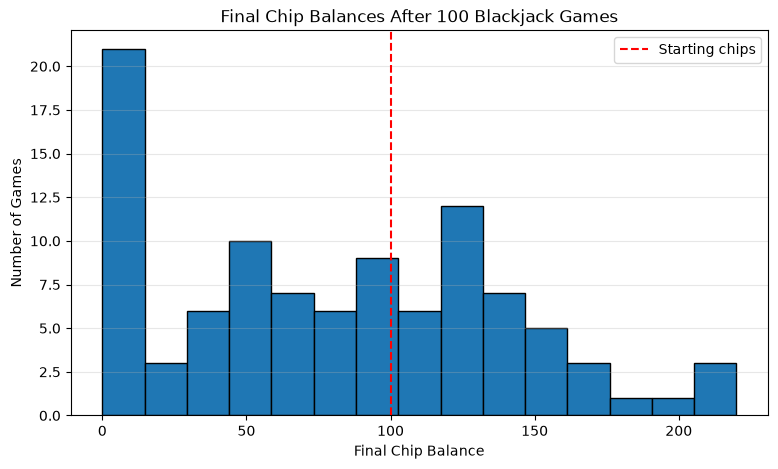


Exercise 8 tests passed!


In [12]:

#  Exercise 8
# Analyze 100 blackjack simulations

import random
import statistics
import matplotlib.pyplot as plt

# Use a seed so the simulation can be repeated
random.seed(42)

# Simulation settings
num_games = 100
max_rounds = 50
starting_chips = 100
bet_amount = 10

# Store the results
final_chips = []
net_winnings = []
rounds_played_list = []


# Run 100 separate blackjack games
for game_number in range(num_games):

    # Create new players for each game
    counter = CountingPlayer("Counter", starting_chips, 0)

    player1 = ComputerPlayer("Computer 1", starting_chips)
    player2 = ComputerPlayer("Computer 2", starting_chips)
    player3 = ComputerPlayer("Computer 3", starting_chips)

    # Start a new blackjack game
    game = CountingBlackjackGame(
        6,
        [counter, player1, player2, player3]
    )

    rounds_played = 0

    # Play up to 50 rounds
    for round_number in range(max_rounds):

        # Stop if the counter cannot afford another bet
        if counter.chips < bet_amount:
            break

        game.play_round(verbose=False, bet=bet_amount)

        rounds_played += 1

    # Save the counting player's results
    final_chips.append(counter.chips)

    winnings = counter.chips - starting_chips
    net_winnings.append(winnings)

    rounds_played_list.append(rounds_played)


# Calculate stats


# Avg final chip balance
mean_chips = statistics.mean(final_chips)

# STD of net winnings across games
std_winnings = statistics.stdev(net_winnings)

# Avg net winnings per round actually played
total_winnings = sum(net_winnings)
total_rounds = sum(rounds_played_list)

average_per_round = total_winnings / total_rounds


# Count profitable and unprofitable games
winning_games = 0
losing_games = 0
even_games = 0

for winnings in net_winnings:

    if winnings > 0:
        winning_games += 1

    elif winnings < 0:
        losing_games += 1

    else:
        even_games += 1


# Calculate probabilities
prob_win = winning_games / num_games
prob_lose = losing_games / num_games
prob_even = even_games / num_games



# Display the results


print("Blackjack Simulation Results")
print("----------------------------")

print("Number of games:", num_games)
print("Maximum rounds per game:", max_rounds)

print("\nAverage final chips:", round(mean_chips, 2))
print("Average net winnings per round:",
      round(average_per_round, 2))

print("Standard deviation of net winnings:",
      round(std_winnings, 2))

print("\nWinning games:", winning_games)
print("Losing games:", losing_games)
print("Even games:", even_games)

print("\nProbability of net winning:",
      round(prob_win, 3))

print("Probability of net losing:",
      round(prob_lose, 3))

print("Probability of breaking even:",
      round(prob_even, 3))



# Create a histogram


plt.figure(figsize=(9, 5))

plt.hist(final_chips, bins=15, edgecolor="black")

# Starting chip balance as a reference
plt.axvline(starting_chips,
            color="red",
            linestyle="--",
            label="Starting chips")

plt.title("Final Chip Balances After 100 Blackjack Games")
plt.xlabel("Final Chip Balance")
plt.ylabel("Number of Games")

plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.show()



# Exercise 8 - Tests


# Checking that all 100 games were recorded
assert len(final_chips) == 100
assert len(net_winnings) == 100
assert len(rounds_played_list) == 100

# Checking the number of rounds in each game
for rounds in rounds_played_list:
    assert 1 <= rounds <= 50

# Checking that the outcomes add up to 100
assert winning_games + losing_games + even_games == 100

# Checking that the probabilities add up to 1
assert abs(prob_win + prob_lose + prob_even - 1) < 0.000001

# Checking that chip balances are not negative
for chips in final_chips:
    assert chips >= 0

print("\nExercise 8 tests passed!")


9. Repeat previous questions scanning the value of the threshold. Try at least 5 different threshold values. Can you find an optimal value?

Card-Counting Threshold Comparison
------------------------------------------------------------------------------
Threshold   Avg/Round     Std Dev       P(Win)      P(Loss)     P(Even)     
-4          -0.63         62.39         0.34        0.62        0.04        
-2          -0.77         62.87         0.25        0.69        0.06        
0           -0.66         64.00         0.28        0.69        0.03        
2           -0.59         59.76         0.28        0.68        0.04        
4           -0.74         65.71         0.27        0.70        0.03        

Best performing threshold: 2
Average winnings per round: -0.59
Probability of net winning: 0.28


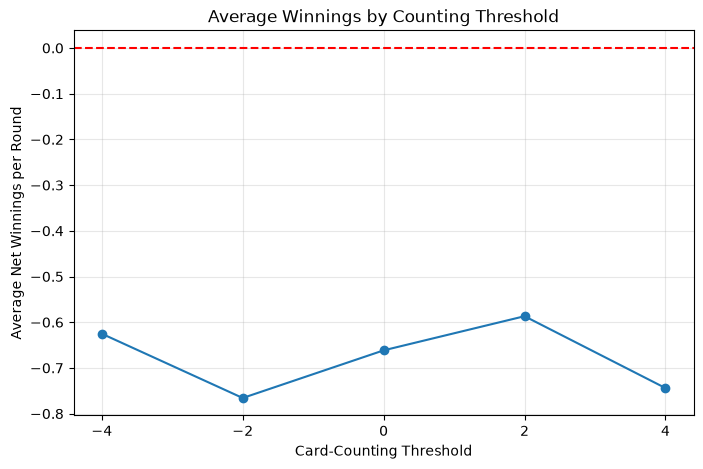

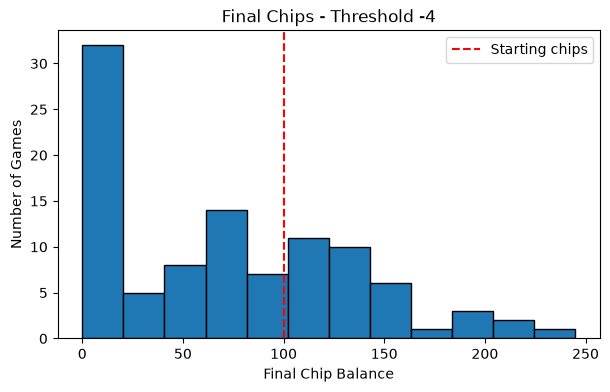

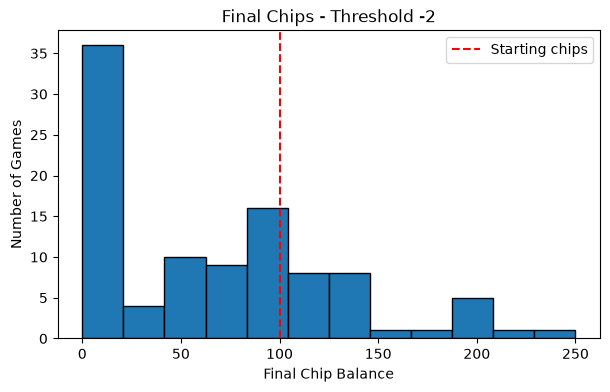

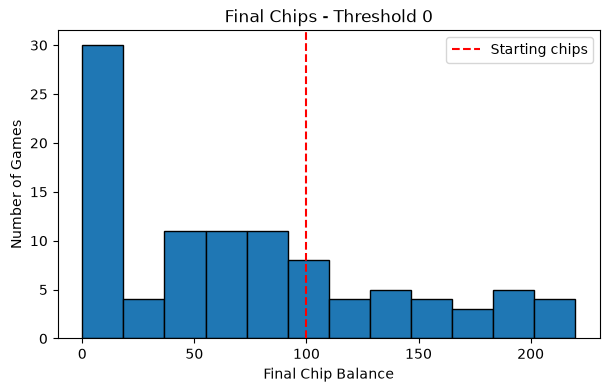

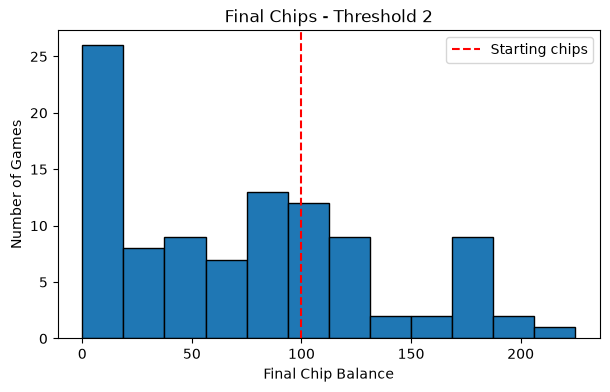

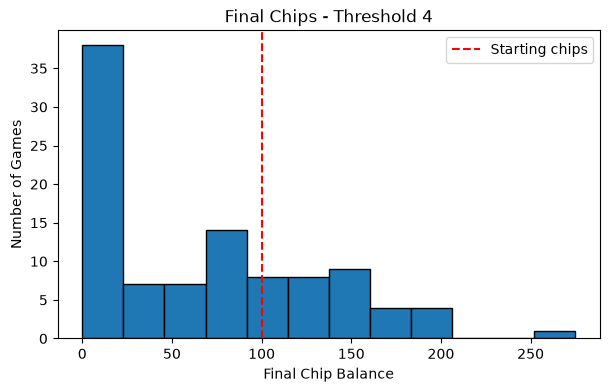


Exercise 9 tests passed!


In [13]:

# Exercise 9
# Comparing different card-counting thresholds

import random
import statistics
import matplotlib.pyplot as plt

# Simulation settings
thresholds = [-4, -2, 0, 2, 4]
num_games = 100
max_rounds = 50
starting_chips = 100
bet_amount = 10

# Stored results for each threshold
results = []



# Test each card-counting threshold


for threshold in thresholds:

    final_chips = []
    net_winnings = []
    rounds_list = []

    # Run 100 games for this threshold
    for game_number in range(num_games):

        # Use the same starting seed for each game number across all thresholds
        random.seed(1000 + game_number)

        # Create a new counting player
        counter = CountingPlayer(
            "Counter", starting_chips, threshold
        )

        # Created three regular computer players
        player1 = ComputerPlayer("Computer 1", starting_chips)
        player2 = ComputerPlayer("Computer 2", starting_chips)
        player3 = ComputerPlayer("Computer 3", starting_chips)

        # Created  a new blackjack game
        game = CountingBlackjackGame(
            6,
            [counter, player1, player2, player3]
        )

        rounds_played = 0

        # Play up to 50 rounds
        for round_number in range(max_rounds):

            # Stop if the counter runs out of chips
            if counter.chips < bet_amount:
                break

            game.play_round(
                verbose=False,
                bet=bet_amount
            )

            rounds_played += 1

        # Record results from this game
        final_chips.append(counter.chips)
        net_winnings.append(counter.chips - starting_chips)
        rounds_list.append(rounds_played)

   
    # Calculate statistics
  

    mean_chips = statistics.mean(final_chips)

    std_winnings = statistics.stdev(net_winnings)

    total_winnings = sum(net_winnings)
    total_rounds = sum(rounds_list)

    average_per_round = total_winnings / total_rounds

    # Count winning, losing, and even games
    wins = 0
    losses = 0
    ties = 0

    for winnings in net_winnings:

        if winnings > 0:
            wins += 1

        elif winnings < 0:
            losses += 1

        else:
            ties += 1

    # Calculate probabilities
    prob_win = wins / num_games
    prob_loss = losses / num_games
    prob_even = ties / num_games

    # Save this threshold's results
    results.append({
        "threshold": threshold,
        "mean_chips": mean_chips,
        "average_per_round": average_per_round,
        "std_winnings": std_winnings,
        "prob_win": prob_win,
        "prob_loss": prob_loss,
        "prob_even": prob_even,
        "final_chips": final_chips,
        "rounds": rounds_list
    })



# Display comparison table


print("Card-Counting Threshold Comparison")
print("-" * 78)

print(f"{'Threshold':<12}"
      f"{'Avg/Round':<14}"
      f"{'Std Dev':<14}"
      f"{'P(Win)':<12}"
      f"{'P(Loss)':<12}"
      f"{'P(Even)':<12}")

for result in results:

    print(f"{result['threshold']:<12}"
          f"{result['average_per_round']:<14.2f}"
          f"{result['std_winnings']:<14.2f}"
          f"{result['prob_win']:<12.2f}"
          f"{result['prob_loss']:<12.2f}"
          f"{result['prob_even']:<12.2f}")



# Finding the best threshold


# Select the threshold with the highest average net winnings per round
best_result = results[0]

for result in results:

    if (result["average_per_round"] >
        best_result["average_per_round"]):

        best_result = result

print("\nBest performing threshold:",
      best_result["threshold"])

print("Average winnings per round:",
      round(best_result["average_per_round"], 2))

print("Probability of net winning:",
      round(best_result["prob_win"], 2))



# Graph 1 (Compare average winnings)


x_values = []
y_values = []

for result in results:
    x_values.append(result["threshold"])
    y_values.append(result["average_per_round"])

plt.figure(figsize=(8, 5))

plt.plot(x_values, y_values, marker="o")
plt.axhline(0, color="red", linestyle="--")

plt.title("Average Winnings by Counting Threshold")
plt.xlabel("Card-Counting Threshold")
plt.ylabel("Average Net Winnings per Round")
plt.xticks(thresholds)
plt.grid(alpha=0.3)

plt.show()


# Graph 2 (Histogram for each threshold)


for result in results:

    plt.figure(figsize=(7, 4))

    plt.hist(
        result["final_chips"],
        bins=12,
        edgecolor="black"
    )

    plt.axvline(
        starting_chips,
        color="red",
        linestyle="--",
        label="Starting chips"
    )

    plt.title(
        "Final Chips - Threshold "
        + str(result["threshold"])
    )

    plt.xlabel("Final Chip Balance")
    plt.ylabel("Number of Games")
    plt.legend()

    plt.show()



# Exercise 9 (Tests)


# Checked that five thresholds were tested
assert len(results) == 5

# Checked that each threshold ran 100 games
for result in results:

    assert len(result["final_chips"]) == 100
    assert len(result["rounds"]) == 100

    # Probabilities should add to 1
    total_probability = (
        result["prob_win"]
        + result["prob_loss"]
        + result["prob_even"]
    )

    assert abs(total_probability - 1) < 0.000001

    # Chip balances cannot be negative
    for chips in result["final_chips"]:
        assert chips >= 0

    # No game exceeds 50 rounds
    for rounds in result["rounds"]:
        assert 1 <= rounds <= 50

# Check that the selected best threshold has the highest observed average
assert best_result["average_per_round"] == max(y_values)

print("\nExercise 9 tests passed!")


10. Create a new strategy based on web searches or your own ideas. Demonstrate that the new strategy will result in increased or decreased winnings. 

Blackjack Strategy Comparison
-----------------------------

Card-Counting Strategy:
Average net winnings: -25.8
Average winnings per round: -0.55
Standard deviation: 60.66
Probability of winning: 0.32

New Dealer-Upcard Strategy:
Average net winnings: -8.4
Average winnings per round: -0.18
Standard deviation: 69.71
Probability of winning: 0.39

Difference in average winnings per round: 0.373
The new strategy performed better in this experiment.


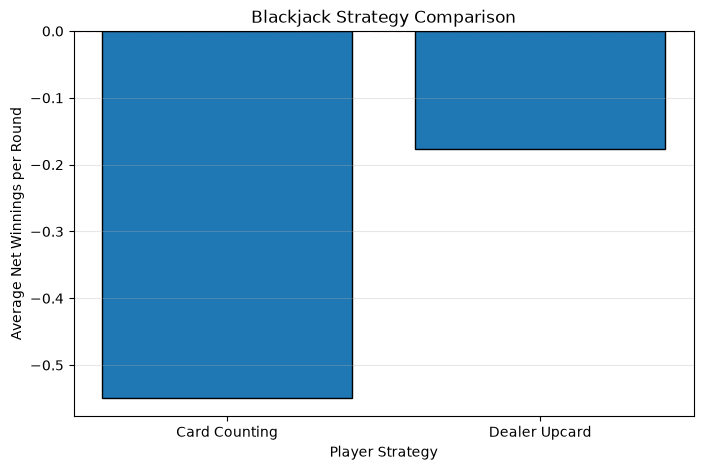


Exercise 10 tests passed!


In [14]:

# Exercise 10
# Comparing a new blackjack strategy with card counting

import random
import statistics
import matplotlib.pyplot as plt


# New strategy based on the dealer's visible card
class UpcardStrategyPlayer(ComputerPlayer):

    def __init__(self, name, chips=100):
        super().__init__(name, chips)
        self.dealer = None

    def choose_action(self):

        # Get the player's hand value
        total = self.hand.value()

        # Look at the dealer's first card
        dealer_card = self.dealer.hand.cards[0]
        dealer_value = dealer_card.value()

        # Always hit on 11 or less
        if total <= 11:
            return "hit"

        # Always stand on 17 or more
        if total >= 17:
            return "stand"

        # With 12, stand if dealer shows 4 to 6
        if total == 12:
            if 4 <= dealer_value <= 6:
                return "stand"
            return "hit"

        # With 13 to 16, stand if dealer shows 2 to 6
        if 2 <= dealer_value <= 6:
            return "stand"

        return "hit"



# Function to simulate a strategy


def simulate_strategy(strategy_name):

    starting_chips = 100
    bet_amount = 10
    num_games = 100
    max_rounds = 50

    winnings_list = []
    final_chips = []
    total_rounds = 0

    # Run 100 separate games
    for game_number in range(num_games):

        # Use matching starting seeds for comparison
        random.seed(2000 + game_number)

        # Select which player strategy to test
        if strategy_name == "counting":
            test_player = CountingPlayer(
                "Strategy Player", starting_chips, 0
            )

        elif strategy_name == "upcard":
            test_player = UpcardStrategyPlayer(
                "Strategy Player", starting_chips
            )

        else:
            raise ValueError("Unknown strategy")

        # Three computer players using dealer rules
        player1 = ComputerPlayer("Computer 1", starting_chips)
        player2 = ComputerPlayer("Computer 2", starting_chips)
        player3 = ComputerPlayer("Computer 3", starting_chips)

        # Create a new game with six decks
        game = CountingBlackjackGame(
            6,
            [test_player, player1, player2, player3]
        )

        # Allow the new player to see the dealer's upcard
        if strategy_name == "upcard":
            test_player.dealer = game.dealer

        # Play up to 50 rounds
        for round_number in range(max_rounds):

            # Stop when the player cannot afford another bet
            if test_player.chips < bet_amount:
                break

            game.play_round(
                verbose=False,
                bet=bet_amount
            )

            total_rounds += 1

        # Calculate net winnings for this game
        winnings = test_player.chips - starting_chips

        winnings_list.append(winnings)
        final_chips.append(test_player.chips)

    # Calculate the statistics
    average_winnings = statistics.mean(winnings_list)
    std_winnings = statistics.stdev(winnings_list)
    average_per_round = sum(winnings_list) / total_rounds

    # Calculate the probability of finishing ahead
    winning_games = 0
    losing_games = 0

    for winnings in winnings_list:

        if winnings > 0:
            winning_games += 1
        elif winnings < 0:
            losing_games += 1

    prob_win = winning_games / num_games
    prob_loss = losing_games / num_games

    # Return all results
    return {
        "average_winnings": average_winnings,
        "std_winnings": std_winnings,
        "average_per_round": average_per_round,
        "prob_win": prob_win,
        "prob_loss": prob_loss,
        "final_chips": final_chips,
        "total_rounds": total_rounds
    }



# Compare the two strategies


count_results = simulate_strategy("counting")
upcard_results = simulate_strategy("upcard")

print("Blackjack Strategy Comparison")
print("-----------------------------")

print("\nCard-Counting Strategy:")
print("Average net winnings:",
      round(count_results["average_winnings"], 2))
print("Average winnings per round:",
      round(count_results["average_per_round"], 2))
print("Standard deviation:",
      round(count_results["std_winnings"], 2))
print("Probability of winning:",
      round(count_results["prob_win"], 3))

print("\nNew Dealer-Upcard Strategy:")
print("Average net winnings:",
      round(upcard_results["average_winnings"], 2))
print("Average winnings per round:",
      round(upcard_results["average_per_round"], 2))
print("Standard deviation:",
      round(upcard_results["std_winnings"], 2))
print("Probability of winning:",
      round(upcard_results["prob_win"], 3))



# Determine whether the new strategy increased or decreased winnings


difference = (
    upcard_results["average_per_round"]
    - count_results["average_per_round"]
)

print("\nDifference in average winnings per round:",
      round(difference, 3))

if difference > 0:
    print("The new strategy performed better in this experiment.")

elif difference < 0:
    print("The new strategy performed worse in this experiment.")

else:
    print("Both strategies had the same average return.")



# Create a comparison graph


strategies = ["Card Counting", "Dealer Upcard"]

averages = [
    count_results["average_per_round"],
    upcard_results["average_per_round"]
]

plt.figure(figsize=(8, 5))

plt.bar(strategies, averages, edgecolor="black")

plt.axhline(0, color="red", linestyle="--")

plt.title("Blackjack Strategy Comparison")
plt.xlabel("Player Strategy")
plt.ylabel("Average Net Winnings per Round")

plt.grid(axis="y", alpha=0.3)
plt.show()



# Exercise 10 Tests


# Check that both simulations recorded 100 games
assert len(count_results["final_chips"]) == 100
assert len(upcard_results["final_chips"]) == 100

# Check that chip balances are not negative
for chips in count_results["final_chips"]:
    assert chips >= 0

for chips in upcard_results["final_chips"]:
    assert chips >= 0

# Test the new strategy with different dealer cards
test_player = UpcardStrategyPlayer("Test Player", 100)
test_dealer = Dealer()
test_player.dealer = test_dealer

# Give the player a hand worth 13
test_player.receive_card(Card("10", "Hearts"))
test_player.receive_card(Card("3", "Clubs"))

# Dealer showing 6: player should stand
test_dealer.receive_card(Card("6", "Spades"))
assert test_player.choose_action() == "stand"

# Dealer showing 10: player should hit
test_dealer.reset_hand()
test_dealer.receive_card(Card("10", "Diamonds"))
assert test_player.choose_action() == "hit"

# Checking that both strategies completed rounds
assert count_results["total_rounds"] > 0
assert upcard_results["total_rounds"] > 0

print("\nExercise 10 tests passed!")
